<a href="https://colab.research.google.com/github/UnnimayaVAshok/Data_Science/blob/main/Class_works/play_tennis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
data = pd.read_csv("play_tennis_dataset.csv")
df = pd.DataFrame(data)
df

,Day,Outlook,Temperature,Humidity,Wind,Play
0,D1,Overcast,Mild,Normal,Strong,Yes
1,D2,Sunny,Mild,Normal,Strong,Yes
2,D3,NaN,Mild,High,Strong,No
3,D4,Sunny,Mild,High,Weak,Yes
4,D5,Sunny,Cool,Normal,Strong,Yes
...,...,...,...,...,...,...
6661,D28,Sunny,Mild,High,Weak,Yes
6662,D29,Rainy,Cool,High,Weak,No
6663,D30,Overcast,Cool,High,Weak,Yes
6664,D31,Sunny,Hot,High,Strong,No


In [ ]:
df.head()

,Day,Outlook,Temperature,Humidity,Wind,Play
0,D1,Overcast,Mild,Normal,Strong,Yes
1,D2,Sunny,Mild,Normal,Strong,Yes
2,D3,NaN,Mild,High,Strong,No
3,D4,Sunny,Mild,High,Weak,Yes
4,D5,Sunny,Cool,Normal,Strong,Yes


In [ ]:
df.tail()

,Day,Outlook,Temperature,Humidity,Wind,Play
6661,D28,Sunny,Mild,High,Weak,Yes
6662,D29,Rainy,Cool,High,Weak,No
6663,D30,Overcast,Cool,High,Weak,Yes
6664,D31,Sunny,Hot,High,Strong,No
6665,D1,Sunny,Cool,Normal,Strong,Yes


In [ ]:
df.shape

(6666, 6)

In [ ]:
df.columns

Index(['Day', 'Outlook', 'Temperature', 'Humidity', 'Wind', 'Play'], dtype='object')

In [ ]:
df.describe()

,Day,Outlook,Temperature,Humidity,Wind,Play
count,6666,6267,6333,6433,6300,6666
unique,31,3,3,2,2,2
top,D1,Overcast,Cool,Normal,Weak,Yes
freq,220,2192,2538,3872,4473,4080


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6666 entries, 0 to 6665
Data columns (total 6 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   Day          6666 non-null   object
 1   Outlook      6267 non-null   object
 2   Temperature  6333 non-null   object
 3   Humidity     6433 non-null   object
 4   Wind         6300 non-null   object
 5   Play         6666 non-null   object
dtypes: object(6)
memory usage: 312.6+ KB


In [ ]:
df = df.drop("Day",axis = 1)
df

,Outlook,Temperature,Humidity,Wind,Play
0,Overcast,Mild,Normal,Strong,Yes
1,Sunny,Mild,Normal,Strong,Yes
2,NaN,Mild,High,Strong,No
3,Sunny,Mild,High,Weak,Yes
4,Sunny,Cool,Normal,Strong,Yes
...,...,...,...,...,...
6661,Sunny,Mild,High,Weak,Yes
6662,Rainy,Cool,High,Weak,No
6663,Overcast,Cool,High,Weak,Yes
6664,Sunny,Hot,High,Strong,No


In [ ]:
df["Play"].value_counts()

,count
Play,
Yes,4080
No,2586


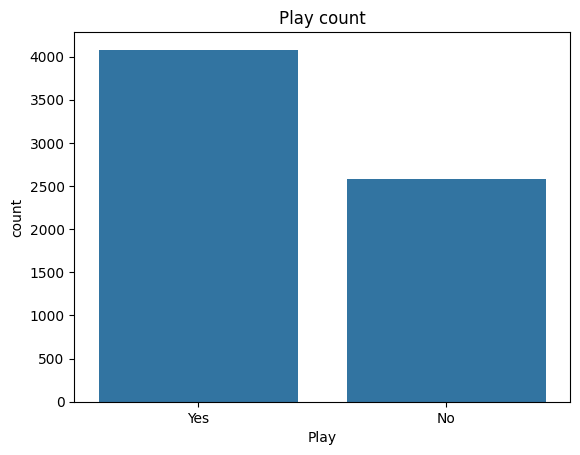

In [ ]:
sns.countplot(x = df["Play"])
plt.title("Play count")
plt.show()

In [ ]:
df.isna().sum()

,0
Outlook,399
Temperature,333
Humidity,233
Wind,366
Play,0


In [ ]:
df["Outlook"] = df["Outlook"].fillna(df["Outlook"].mode()[0])
df["Temperature"] = df["Temperature"].fillna(df["Temperature"].mode()[0])
df["Humidity"] = df["Humidity"].fillna(df["Humidity"].mode()[0])
df["Wind"] = df["Wind"].fillna(df["Wind"].mode()[0])

In [ ]:
df.isna().sum()

,0
Outlook,0
Temperature,0
Humidity,0
Wind,0
Play,0


In [ ]:
df.duplicated().sum()

np.int64(6607)

In [ ]:
df = df.drop_duplicates()
df.duplicated().sum()

np.int64(0)

In [ ]:
X = df.drop("Play",axis = 1)
y = df["Play"]
X,y

(       Outlook Temperature Humidity    Wind
 0     Overcast        Mild   Normal  Strong
 1        Sunny        Mild   Normal  Strong
 2     Overcast        Mild     High  Strong
 3        Sunny        Mild     High    Weak
 4        Sunny        Cool   Normal  Strong
 5     Overcast        Cool   Normal  Strong
 7        Sunny        Mild   Normal    Weak
 8        Rainy        Mild   Normal    Weak
 9        Rainy        Cool     High    Weak
 12       Rainy         Hot   Normal    Weak
 13       Sunny        Cool   Normal    Weak
 15    Overcast        Mild     High  Strong
 16    Overcast        Mild     High    Weak
 17       Sunny        Cool     High    Weak
 18    Overcast        Mild     High    Weak
 19       Rainy         Hot     High  Strong
 20       Rainy        Cool     High  Strong
 22    Overcast        Cool   Normal    Weak
 27       Sunny        Cool     High  Strong
 28    Overcast        Mild   Normal    Weak
 29       Rainy        Cool   Normal  Strong
 30    Ove

In [ ]:
X = pd.get_dummies(X)
X

,Outlook_Overcast,Outlook_Rainy,Outlook_Sunny,Temperature_Cool,Temperature_Hot,Temperature_Mild,Humidity_High,Humidity_Normal,Wind_Strong,Wind_Weak
0,True,False,False,False,False,True,False,True,True,False
1,False,False,True,False,False,True,False,True,True,False
2,True,False,False,False,False,True,True,False,True,False
3,False,False,True,False,False,True,True,False,False,True
4,False,False,True,True,False,False,False,True,True,False
5,True,False,False,True,False,False,False,True,True,False
7,False,False,True,False,False,True,False,True,False,True
8,False,True,False,False,False,True,False,True,False,True
9,False,True,False,True,False,False,True,False,False,True
12,False,True,False,False,True,False,False,True,False,True


In [ ]:
from sklearn.model_selection import train_test_split

X_train,X_test,y_train,y_test = train_test_split(X,y,test_size = 0.3,random_state = 42,stratify = y)

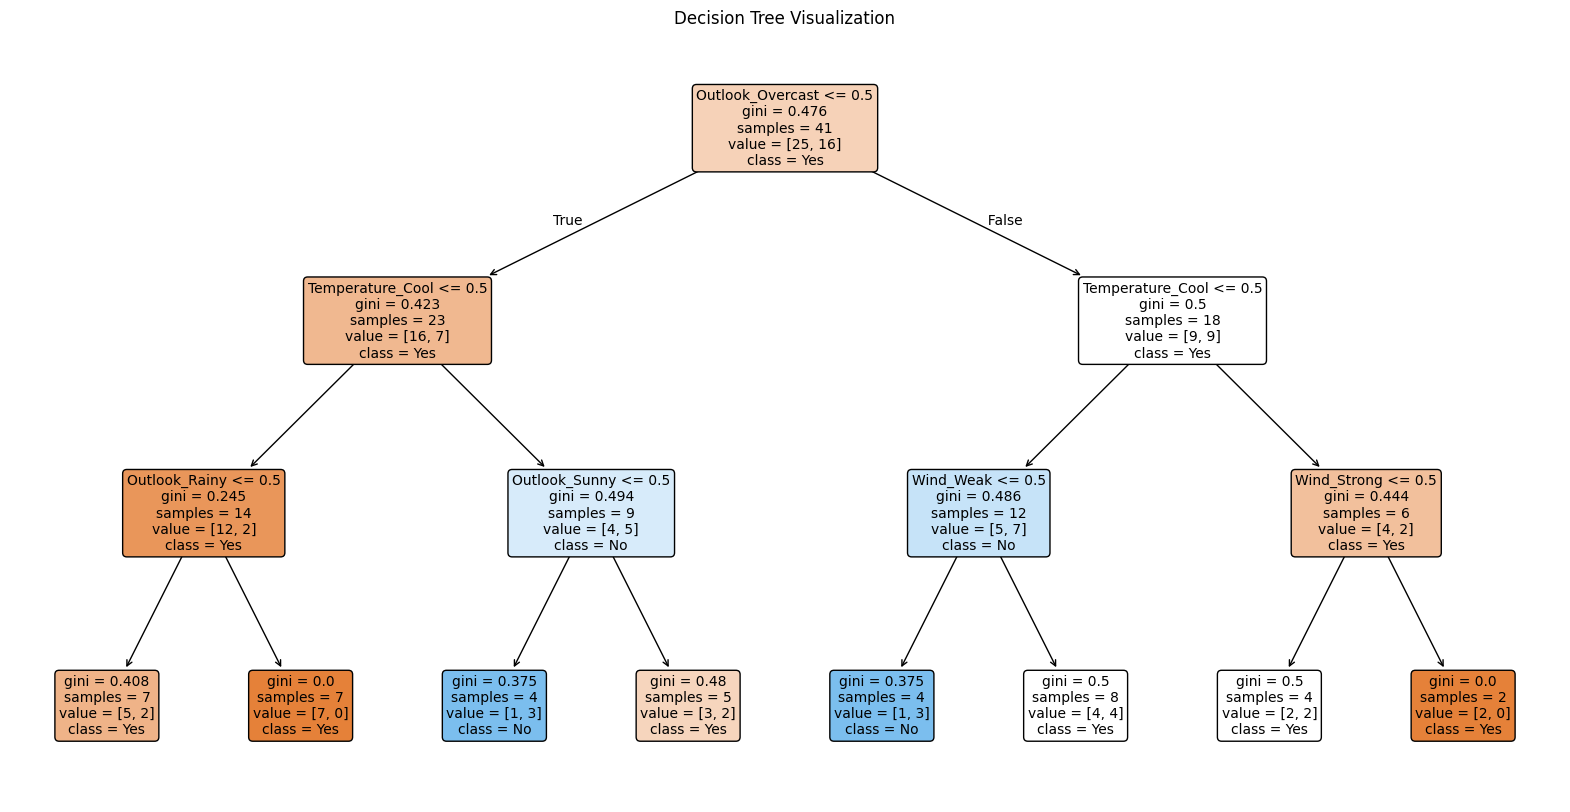

In [ ]:
from sklearn.tree import DecisionTreeClassifier,plot_tree

clf = DecisionTreeClassifier(max_depth = 3,random_state = 42)
clf.fit(X_train,y_train)

plt.figure(figsize=(20,10))
plot_tree(
    clf,
    feature_names=list(X.columns),
    class_names=list(y.unique()),
    filled=True,
    rounded=True,
    fontsize=10
)
plt.title("Decision Tree Visualization")
plt.show()


In [ ]:
model = DecisionTreeClassifier(criterion = "entropy")
model.fit(X_train,y_train)
y_pred = model.predict(X_test)
y_pred

array(['Yes', 'No', 'Yes', 'No', 'Yes', 'No', 'No', 'No', 'No', 'No',
       'No', 'No', 'No', 'Yes', 'No', 'No', 'No', 'Yes'], dtype=object)

In [ ]:
from sklearn.metrics import accuracy_score,recall_score,confusion_matrix,classification_report

print(accuracy_score(y_test,y_pred))
#print(recall_score(y_test,y_pred))
print(confusion_matrix(y_test,y_pred))
print(classification_report(y_test,y_pred))

0.3333333333333333
[[6 5]
 [7 0]]
              precision    recall  f1-score   support

          No       0.46      0.55      0.50        11
         Yes       0.00      0.00      0.00         7

    accuracy                           0.33        18
   macro avg       0.23      0.27      0.25        18
weighted avg       0.28      0.33      0.31        18

